In [237]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix


In [184]:
#load and read dataset

df=pd.read_csv("/content/heart_disease.csv")

In [185]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [186]:
df.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1
1024,54,1,0,120,188,0,1,113,0,1.4,1,1,3,0


In [187]:
#check shape

df.shape

(1025, 14)

In [188]:
#check datatype
df.dtypes

,0
age,int64
sex,int64
cp,int64
trestbps,int64
chol,int64
fbs,int64
restecg,int64
thalach,int64
exang,int64
oldpeak,float64


In [189]:
df.duplicated().sum()

np.int64(723)

In [190]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [191]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [192]:
#missing values

df.isna().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [193]:
#identify numerical columns
numerical_cols = df.select_dtypes(include="number").columns
numerical_cols


Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

ValueError: num must be an integer with 1 <= num <= 9, not 10

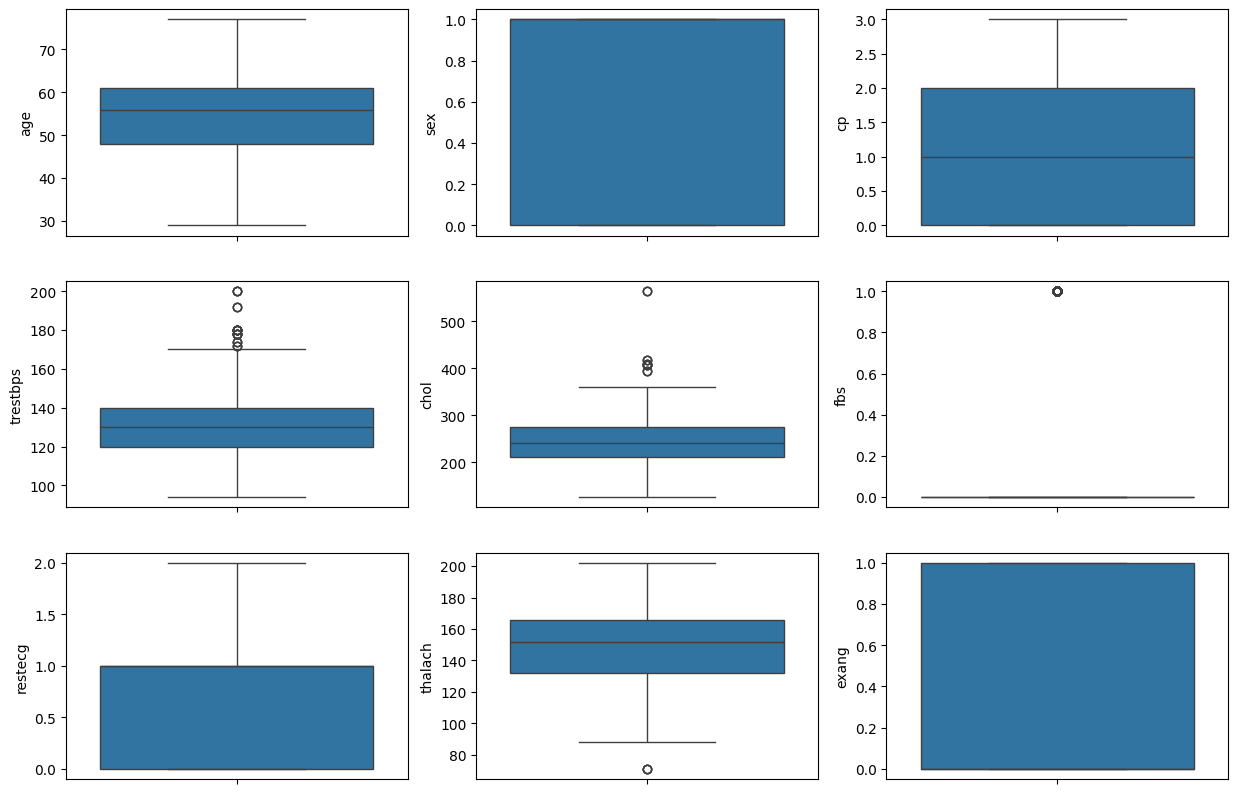

In [194]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col])

plt.tight_layout()
plt.show()

In [195]:

#identify category columns
category_cols = df.select_dtypes(include="number").columns
category_cols

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

#Step 2: Data Cleaning and Preprocessing

In [196]:
df.isna().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [197]:
# Handle outliers in chol and trestbps using IQR

for col in ['chol', 'trestbps']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)


In [198]:
# One-hot encoding

encoder = OneHotEncoder(drop='first', sparse_output=False)
encoded = encoder.fit_transform(df[['cp', 'restecg', 'thal']])
encoded_df = pd.DataFrame(encoded,columns=encoder.get_feature_names_out(['cp', 'restecg', 'thal']),index=df.index)
encoded_df.head()


,cp_1,cp_2,cp_3,restecg_1,restecg_2,thal_1,thal_2,thal_3
0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [199]:
#Scaling

scaler = StandardScaler()
features = ['trestbps', 'chol', 'thalach', 'oldpeak']
df[features] = scaler.fit_transform(df[features])


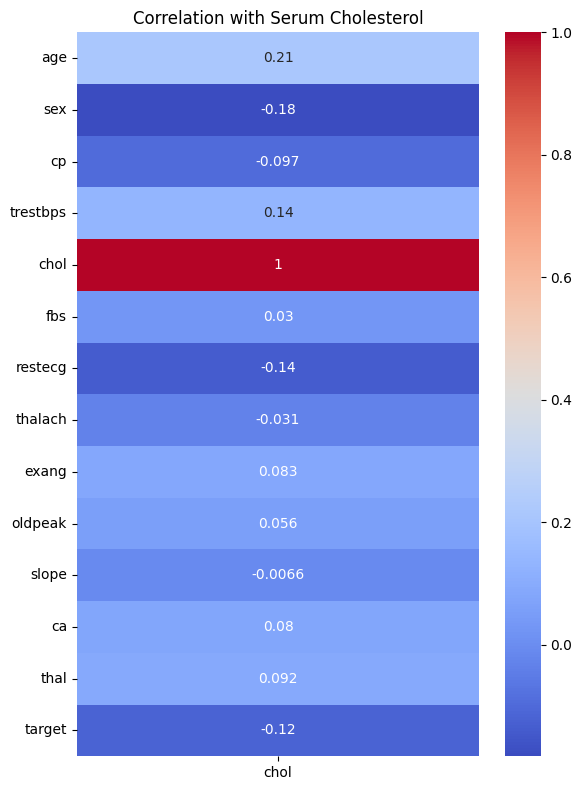

In [201]:
#correlation for regression
chol_corr = df.select_dtypes(include='number').corr()[["chol"]]
plt.figure(figsize=(6, 8))
sns.heatmap(chol_corr,cmap="coolwarm",annot=True)
plt.title("Correlation with Serum Cholesterol")
plt.tight_layout()
plt.show()

In [202]:
target_corr = chol_corr["chol"].abs()
selected_features = target_corr[target_corr >= 0.12].index.tolist()
selected_features.remove("chol")
print("Selected features:")
print(selected_features)


Selected features:
['age', 'sex', 'trestbps', 'restecg']


In [203]:
X_reg = df[selected_features]
y_reg = df["chol"]


In [204]:
#Train Test Split

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg,y_reg,test_size=0.20,random_state=42)


#Selecting Models

In [205]:
X_reg.head()

,age,sex,trestbps,restecg
0,52,1,-0.378869,1
1,53,1,0.528894,0
2,70,1,0.831481,1
3,61,1,1.013034,1
4,62,0,0.407859,1


In [206]:
#LinearRegression
linear_model = LinearRegression()
linear_model.fit(X_train_reg, y_train_reg)



LinearRegression()

In [207]:
#prediction
new_data = [[53,1,0.528894,0]]
new_data_scaled = scaler.transform(new_data)
result = linear_model.predict(new_data_scaled)
print("Prediction:", result)

Prediction: [0.58040178]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [209]:
y_pred_train = linear_model.predict(X_train_reg)
y_pred_test = linear_model.predict(X_test_reg)

In [211]:
#SVM
svm_model = SVR(kernel="rbf")
svm_model.fit(X_train_reg, y_train_reg)

SVR()

In [212]:
#prediction
new_data = [[53,1,0.528894,0]]
new_data_scaled = scaler.transform(new_data)
result = svm_model.predict(new_data_scaled)
print("Prediction:", result)

Prediction: [-1.58079155]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVR was fitted with feature names
  warnings.warn(


In [214]:
y_pred_train = svm_model.predict(X_train_reg)
y_pred_test = svm_model.predict(X_test_reg)

In [249]:

#RandomForest
rf_model = RandomForestRegressor(n_estimators=100,random_state=42)
rf_model.fit(X_train_reg, y_train_reg)

RandomForestRegressor(random_state=42)

In [217]:
#prediction
new_data = [[53,1,0.528894,0]]
new_data_scaled = scaler.transform(new_data)
result = rf_model.predict(new_data_scaled)
print("Prediction:", result)

Prediction: [-0.96309103]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


In [219]:
y_pred_train = rf_model.predict(X_train_reg)
y_pred_test = rf_model.predict(X_test_reg)

#Step 5: Evaluate Models on Test Data Regression

In [248]:
mae = mean_absolute_error(y_test_reg, y_pred_test)
mse = mean_squared_error(y_test_reg, y_pred_test)
r2 = r2_score(y_test_reg, y_pred_test)

print("Linear Regression")
print("MAE :", mae)
print("MSE :", mse)
print("R²  :", r2)

Linear Regression
MAE : 0.2806906685352595
MSE : 0.1851188511820302
R²  : 0.8257504233544397


In [251]:
#svm
mae_svm = mean_absolute_error(y_test_reg, y_pred_test)
mse_svm = mean_squared_error(y_test_reg, y_pred_test)
r2_svm = r2_score(y_test_reg, y_pred_test)
print("SVM")
print("MAE :", mae_svm)
print("MSE :", mse_svm)
print("R²  :", r2_svm)


SVM
MAE : 0.2806906685352595
MSE : 0.1851188511820302
R²  : 0.8257504233544397


In [252]:
#RF
mae_rf = mean_absolute_error(y_test_reg, y_pred_rf)
mse_rf = mean_squared_error(y_test_reg, y_pred_rf)
r2_rf = r2_score(y_test_reg, y_pred_rf)
print("\nRandom Forest Regression")
print("MAE :", mae_rf)
print("MSE :", mse_rf)
print("R²  :", r2_rf)



Random Forest Regression
MAE : 1.0563856199984596
MSE : 1.5916088763945733
R²  : -0.498157379036241


#Classification

In [221]:
# Classification
X_class = df.drop(columns=["target"])
y_class = df["target"]

In [222]:

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(X_class, y_class,test_size=0.2,random_state=42,stratify=y_class)

In [223]:
# Scaling
scaler = StandardScaler()
X_train_class_scaled = scaler.fit_transform(X_train_class)
X_test_class_scaled = scaler.transform(X_test_class)


In [224]:
logistic_model = LogisticRegression(max_iter=1000,random_state=42)
logistic_model.fit(X_train_class_scaled,y_train_class)

LogisticRegression(max_iter=1000, random_state=42)

In [225]:
y_pred_logistic = logistic_model.predict(X_test_class_scaled)

In [226]:
knn_model = KNeighborsClassifier( n_neighbors=5)
knn_model.fit(X_train_class_scaled,y_train_class)

KNeighborsClassifier()

In [227]:
y_pred_knn = knn_model.predict(X_test_class_scaled)

In [228]:
rf_model = RandomForestClassifier(n_estimators=100,random_state=42)
rf_model.fit(X_train_class,y_train_class)


RandomForestClassifier(random_state=42)

In [229]:
y_pred_rf = rf_model.predict(X_test_class)


#Evaluate Models on Test Data Classification

In [235]:

# Evaluation
print("Logistic Regression")
print("Accuracy:", accuracy_score(y_test_class, y_pred_logistic))
print("Precision:", precision_score(y_test_class, y_pred_logistic))
print("Recall:", recall_score(y_test_class, y_pred_logistic))
print("F1-Score:", f1_score(y_test_class, y_pred_logistic))


Logistic Regression
Accuracy: 0.8097560975609757
Precision: 0.7619047619047619
Recall: 0.9142857142857143
F1-Score: 0.8311688311688312


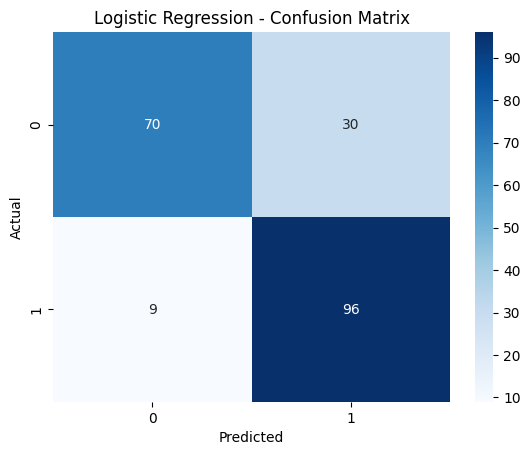

In [240]:
cm = confusion_matrix(y_test_class, y_pred_logistic)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [242]:
# Evaluate
print("KNN")
print("Accuracy:", accuracy_score(y_test_class, y_pred_knn))
print("Precision:", precision_score(y_test_class, y_pred_knn))
print("Recall:", recall_score(y_test_class, y_pred_knn))
print("F1-Score:", f1_score(y_test_class, y_pred_knn))

KNN
Accuracy: 0.8682926829268293
Precision: 0.8823529411764706
Recall: 0.8571428571428571
F1-Score: 0.8695652173913043


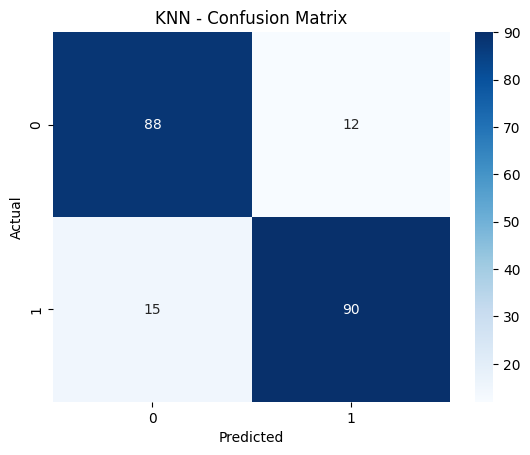

In [244]:
cm = confusion_matrix(y_test_class, y_pred_knn)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN - Confusion Matrix")
plt.show()

In [245]:
print("Random Forest")
print("Accuracy:", accuracy_score(y_test_class, y_pred_rf))
print("Precision:", precision_score(y_test_class, y_pred_rf))
print("Recall:", recall_score(y_test_class, y_pred_rf))
print("F1-Score:", f1_score(y_test_class, y_pred_rf))

Random Forest
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-Score: 1.0


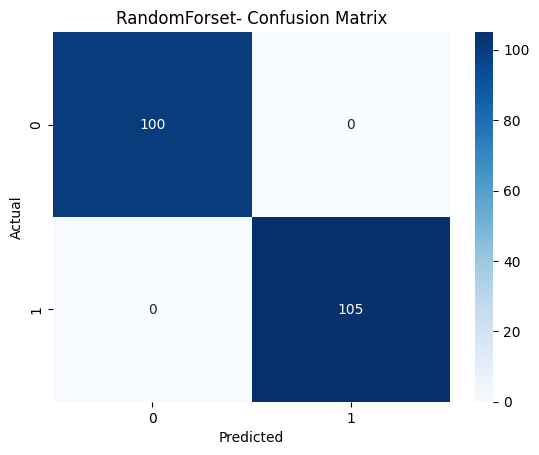

In [246]:
cm = confusion_matrix(y_test_class, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("RandomForset- Confusion Matrix")
plt.show()

#Result

For regression, Linear Regression and SVM perform equally well .They have the lowest MAE and MSE and the highest R² value.
Best performing regression models: Linear Regression and SVM

For classification, Random Forest achieved the highest values for Accuracy, Precision, Recall, and F1-Score, with all metrics equal to 1.00
Best performing classification model: Random Forest.




